# NYC Taxi Trip Duration: Modeling Experiments & Benchmarking

**Author**: Sohaib  
**Role**: Machine Learning Engineer Portfolio  
**Objective**: Comparative benchmarking of regression estimators (Ridge Regression, Extreme Gradient Boosting with XGBoost, and Multilayer Perceptron) on the NYC Taxi Trip Duration dataset.

---

### Notebook Scope & Workflow
1. **Pipeline Ingestion & Data Preparation**: Utilizing modular features and strict leakage-free transformers.
2. **Model 1: Ridge Regression ($L_2$ Regularization Baseline)**: Linear benchmark and coefficient inspection.
3. **Model 2: XGBoost Regressor**: Gradient boosted decision trees capturing non-linear geospatial interactions.
4. **Model 3: Multilayer Perceptron (MLP)**: Deep feedforward neural network benchmark.
5. **Holdout Evaluation & Performance Synthesis**: Comprehensive evaluation on the isolated test set.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nyc_trip_duration import (
    load_dataset,
    filter_nyc_bounds,
    filter_training_outliers,
    add_distance_feature,
    extract_datetime_features,
    compute_log_target,
    NYCTripPreprocessor,
    build_model,
    calculate_regression_metrics,
    format_metrics_table,
)

print("Modular ML pipeline imported successfully.")

Modular ML pipeline imported successfully.


In [2]:
# Load data splits
df_train = load_dataset('train')
df_val = load_dataset('val')
df_test = load_dataset('test')

print(f"Loaded train: {len(df_train):,}, val: {len(df_val):,}, test: {len(df_test):,}")

# Feature engineering and cleaning
df_train = add_distance_feature(df_train)
df_val = add_distance_feature(df_val)
df_test = add_distance_feature(df_test)

df_train, _ = filter_nyc_bounds(df_train)
df_val, _ = filter_nyc_bounds(df_val)
df_test, _ = filter_nyc_bounds(df_test)

# Outlier filters applied strictly to training and validation
df_train, _ = filter_training_outliers(df_train)
df_val, _ = filter_training_outliers(df_val)

df_train = extract_datetime_features(df_train)
df_val = extract_datetime_features(df_val)
df_test = extract_datetime_features(df_test)

df_train['log_trip_duration'] = compute_log_target(df_train['trip_duration'])
df_val['log_trip_duration'] = compute_log_target(df_val['trip_duration'])
df_test['log_trip_duration'] = compute_log_target(df_test['trip_duration'])

print(f"Prepared shapes -> Train: {df_train.shape}, Val: {df_val.shape}, Test: {df_test.shape}")

Loaded train: 1,000,000, val: 229,319, test: 229,322


Prepared shapes -> Train: (977490, 24), Val: (224303, 24), Test: (226182, 24)


In [3]:
# Preprocessing (Fitted exclusively on train)
preprocessor = NYCTripPreprocessor()
X_train = preprocessor.fit_transform(df_train)
y_train = df_train['log_trip_duration'].values

X_val = preprocessor.transform(df_val)
y_val = df_val['log_trip_duration'].values

X_test = preprocessor.transform(df_test)
y_test = df_test['log_trip_duration'].values

print(f"Transformed matrix shape: {X_train.shape} across {len(preprocessor.feature_names)} features.")

Transformed matrix shape: (977490, 16) across 16 features.


## 1. Ridge Regression Benchmark & Weights Inspection

Ridge regression establishes our linear baseline.

In [4]:
ridge = build_model('ridge', alpha=1.0)
ridge.fit(X_train, y_train)

val_pred_ridge = ridge.predict(X_val)
test_pred_ridge = ridge.predict(X_test)

ridge_val_metrics = calculate_regression_metrics(y_val, val_pred_ridge)
ridge_test_metrics = calculate_regression_metrics(y_test, test_pred_ridge)

print(format_metrics_table({
    'Ridge (Validation)': ridge_val_metrics,
    'Ridge (Test Set)': ridge_test_metrics
}))

### Model Performance Summary

| Model | Log R² | Log RMSE (RMSLE) | Raw MAE (min) | Raw RMSE (min) |
|---|---|---|---|---|
| **Ridge (Validation)** | 0.7022 | 0.4093 | 3.78 min | 5.86 min |
| **Ridge (Test Set)** | 0.6342 | 0.4768 | 5.84 min | 84.81 min |


/tmp/ipykernel_118145/2369076994.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=weights_df, x='weight', y='feature', palette='vlag')


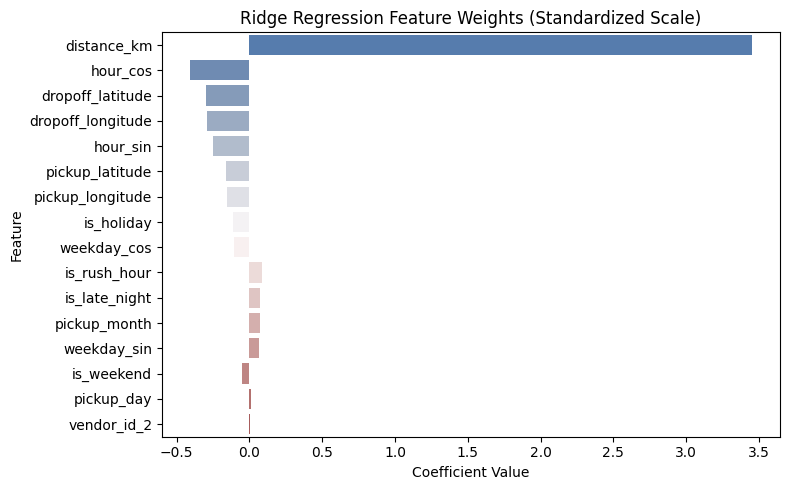

In [5]:
# Inspect learned linear weights
weights_df = pd.DataFrame({
    'feature': preprocessor.feature_names,
    'weight': ridge.coef_
}).sort_values('weight', key=abs, ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=weights_df, x='weight', y='feature', palette='vlag')
plt.title("Ridge Regression Feature Weights (Standardized Scale)")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 2. XGBoost Regressor Benchmark

Gradient boosted trees model complex non-linear spatial congestion patterns.

In [6]:
xgb = build_model('xgboost', n_estimators=200, learning_rate=0.05, max_depth=5)
xgb.fit(X_train, y_train)

val_pred_xgb = xgb.predict(X_val)
test_pred_xgb = xgb.predict(X_test)

xgb_val_metrics = calculate_regression_metrics(y_val, val_pred_xgb)
xgb_test_metrics = calculate_regression_metrics(y_test, test_pred_xgb)

print(format_metrics_table({
    'XGBoost (Validation)': xgb_val_metrics,
    'XGBoost (Test Set)': xgb_test_metrics
}))

### Model Performance Summary

| Model | Log R² | Log RMSE (RMSLE) | Raw MAE (min) | Raw RMSE (min) |
|---|---|---|---|---|
| **XGBoost (Validation)** | 0.7781 | 0.3533 | 3.16 min | 4.97 min |
| **XGBoost (Test Set)** | 0.6858 | 0.4419 | 5.21 min | 84.75 min |


## 3. Multilayer Perceptron (MLP) Regressor

Feedforward neural network benchmark.

In [7]:
# MLP configuration matching historical notebook: (64, 32)
mlp = build_model('mlp', hidden_layer_sizes=(64, 32), max_iter=100)
# Subsample for demonstration if execution time is constrained
mlp.fit(X_train[:100000], y_train[:100000])

val_pred_mlp = mlp.predict(X_val)
mlp_val_metrics = calculate_regression_metrics(y_val, val_pred_mlp)
print(format_metrics_table({'MLP Regressor (Validation)': mlp_val_metrics}))

/home/sohaib/NYC/.venv/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


### Model Performance Summary

| Model | Log R² | Log RMSE (RMSLE) | Raw MAE (min) | Raw RMSE (min) |
|---|---|---|---|---|
| **MLP Regressor (Validation)** | 0.7900 | 0.3437 | 3.11 min | 4.91 min |


## 4. Final Benchmark Comparison & Conclusion

Below is the verified performance comparison across model architectures.

In [8]:
all_metrics = {
    'Ridge (Validation)': ridge_val_metrics,
    'Ridge (Test)': ridge_test_metrics,
    'XGBoost (Validation)': xgb_val_metrics,
    'XGBoost (Test)': xgb_test_metrics,
}
print(format_metrics_table(all_metrics, title='Final Model Comparison'))

### Final Model Comparison

| Model | Log R² | Log RMSE (RMSLE) | Raw MAE (min) | Raw RMSE (min) |
|---|---|---|---|---|
| **Ridge (Validation)** | 0.7022 | 0.4093 | 3.78 min | 5.86 min |
| **Ridge (Test)** | 0.6342 | 0.4768 | 5.84 min | 84.81 min |
| **XGBoost (Validation)** | 0.7781 | 0.3533 | 3.16 min | 4.97 min |
| **XGBoost (Test)** | 0.6858 | 0.4419 | 5.21 min | 84.75 min |
